# Time Series Proj. Part 2

Testing whether the monetary polciy surprise $mps_t$ built in Part 1 can be **predicted** with information that was publicly availible *before* the ECB announcement.

Each group regresses its **monthly** surprise on a constant and a vector of predictors measured before the annoucement:

$mps_t = \alpha + β' z_{t-1} + u_t$, and tests whether the elements of $\beta$ are individualsly and jointly zero.

$H0: \beta = 0$, the surprise cannot be predicted with information available before the announcement.

$HA: \beta ≠ 0$


Previously shown that US monetary policy surprises are correlated with macroeconomic and financial news released before the FOMC meeting.

## Creation of the Monthly Surprise dependent variable: $mps_t$

Start from the daily surprise of Part 1, one row per ECB announcement. Convert it to a monthly series by summing the daily surprises within each month.

$mps_t = \sum_{d \in month:t} mps_d $

Since 2002, there is at most one ME per month in almost all months, so the sum is usually just the value on the announcement day. Months wihtout an ECB announcement are kepy, with $mps_t = 0$, **CANNOT DROP**.

With the sample of Part 1: Jan. 2002 to Oct. 2025, $T = 286$, report how many of them contain an announcement.

# Predictors $z_{t-1}$

**All predictors are changes measured stricly before the annoucement** so that they were known to market participants when the ECB announced its decision. Because months without an announcement are kept, every month t needs a *reference day* $r_t$.

## $r_t$

+ in months without an announcement on day d: $r_t = d - 1$, the last trading day before the announcement.
+ in months wihtout an announcement: $r_t$ = last trading day of the month $t - 1$.

A simpler alternative is to use the last trading day of the month $t-1$  as $r_t$ for *all* months: the definition is then the same for every month and still uses only information available beofre any announcement in month t, at the cost of ignoring news between the start of the month and the meeting. State which convention you use. In the table, $d - 1$ stands for $r_t$. The table gives the definition, the frequency, the source and how to download each variable.

**Nota Bene**: only the ESI and inflation are Eurostat series, the equity, $\alpha$ and yield-curve data comes from STOXX and the ECB.



## Dataset Query + Concat

### What DF Needs

| predictor | freq | where to get |
| --------- | --------- | --------- |
| STOXX | daily | EURO STOXX, Yahoo Finance ticker ^STOXX50E,  (R: quantmod::getSymbols) |
| VSTOXX | daily | VSTOXX, symbol V2TX, stoxx.com |
| ESI | monthly | Eurostat dataset teibs010 |
| Inflation | monthly | eurostat ds prc_hicp_manr (all items CP00, euro area EA) |
| Yield-Curve PC2 | daily | ECB data portal, dataset YC: AAA government bond spot rates, e.g. YC.B.U2.EUR.4F.G N A. SV C YM.SR 1Y (replace 1Y by 3M, 6M, 2Y, 5Y, 10Y, . . . ) |

**Timing and look-ahead bias quick notes**



A predictor is valid only if it was published before the announcement.


+ daily market data are observed every day: use the closing value of the day **before** the announcement, $d-1$, never the announcement day itself, $t$
+ the ESI for month $t$ is published at the end of month $t$, usually after the ECB meting.
  + use $ESI_{t-1} - ESI_{t-4}$, the latest published value against three months earlier, or justify a diff. choice
+ the flash HICP for month $t-1$ is published at the end of the month or the start of the month t, before most ECB meetings, so $\pi_{t-1}$ is known at the time of the meeting.


In [ ]:
# @title

# csvs locally saved just incase in files
"""
# stoxx query
getSymbols('^STOXX50E', src = 'yahoo')

# v2tx query
v2tx <- read.csv('v2tx.csv')

# esi query SEASONALLY ADJUSTED ALR
esi <- read.csv('esi.csv')

# inflation all items CP00, EA
inflation <- read.csv('inflation.csv')

# yc of 3 month, not sure how many freq. we need
# gonna pca this covariate, so we can choose how many freq. we wanna use
# e.g. 3m, 6m, 1y
yc3m <- read.csv('yc_3m.csv')
yc6m <- read.csv('yc_6m.csv')
yc1y <- read.csv('yc_1y.csv')
yc2y <- read.csv('yc_2y.csv')
yc5y <- read.csv('yc_5y.csv')
yc10y <- read.csv('yc_10y.csv')"""


ERROR: Error in parse(text = input): <text>:4:3: unexpected string constant
24: yc5y <- read.csv('yc_5y.csv')
25: yc10y <- read.csv('yc_10y.csv')"
      ^


In [ ]:
install.packages(c("eurostat", "ecb", "quantmod", "sandwich", "lmtest"))
library(eurostat); library(ecb); library(quantmod)
clean_eurostat_cache()

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Deleted .rds/.RData files and cache_list.json from /tmp/RtmpwB6pAb/eurostat



# Yield Curve Notes

Take the spot rates for several maturities, (3m, 6m, 1y, 2y, 5y, 10y), conduct pca of the levels of the whole sample. **KEEP PC 2, SLOPE**, normalize the sign so that it is positively correlated with the spread (e.g.) y^{10Y} - y^{3M}. Then compute its change from three months before to the day before each announcement. A simpler robustness check is to use the change in the spread (e.g.) y^{10Y} - y^{3M} directly, which used the change in the slope of the yield curve.

## Other Potential Predictos

Also have the freedom to add variables similar to other literature examples.

e.g:

+ three-month log change in a commodity price index (Brent oil price, ECB Data Portal, FRED),
+ the change in the euro-dollar xr (ECB reference rates, dataset EXR),
+ data surprises (actual minus expected releases). Justify any addition if needed.

# **(i) Build the Monthly Surprise**.

Aggregate your daily surprise to monthly frequency, setting $mps_t = 0$ in months without an announcement, and report T, the number of announcement months, the sample period, and the mean, std dev, min, and max of $mps_t$. Plot the monthly series.

In [ ]:
install.packages(
  c("dplyr", "tidyr", "lubridate"),
  repos = "https://cloud.r-project.org"
)

library(dplyr)
library(tidyr)
library(lubridate)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
mps <- read.csv("mps.csv")

monthly_mps <- mps %>%
  mutate(month = floor_date(as.Date(date), "month")) %>%
  group_by(month) %>%
  summarise(
    unstandardized = sum(as.numeric(unstandardized), na.rm = TRUE),
    .groups = "drop"
  ) %>%
  complete(
    month = seq.Date(min(month), max(month), by = "month"),
    fill = list(unstandardized = 0)
  ) %>%
  mutate(
    month_date = month,
    month = format(month, "%Y-%m")
  )

head(monthly_mps)


month,unstandardized,month_date
<chr>,<dbl>,<date>
2002-01,0.4342315,2002-01-01
2002-02,2.6200959,2002-02-01
2002-03,1.1732497,2002-03-01
2002-04,-1.2746828,2002-04-01
2002-05,3.8277999,2002-05-01
2002-06,0.7070808,2002-06-01


Length of monthly_mps: 
[1] 286
sample period 
************************************************** 
start period of sample:  2002-01end period of sample:  2025-10

,unstandardized
Mean,-1.911843e-16
Std_Dev,2.495350e+00
Min,-1.071652e+01
Max,1.059272e+01


Warning message:
“Unknown or uninitialised column: `mps`.”


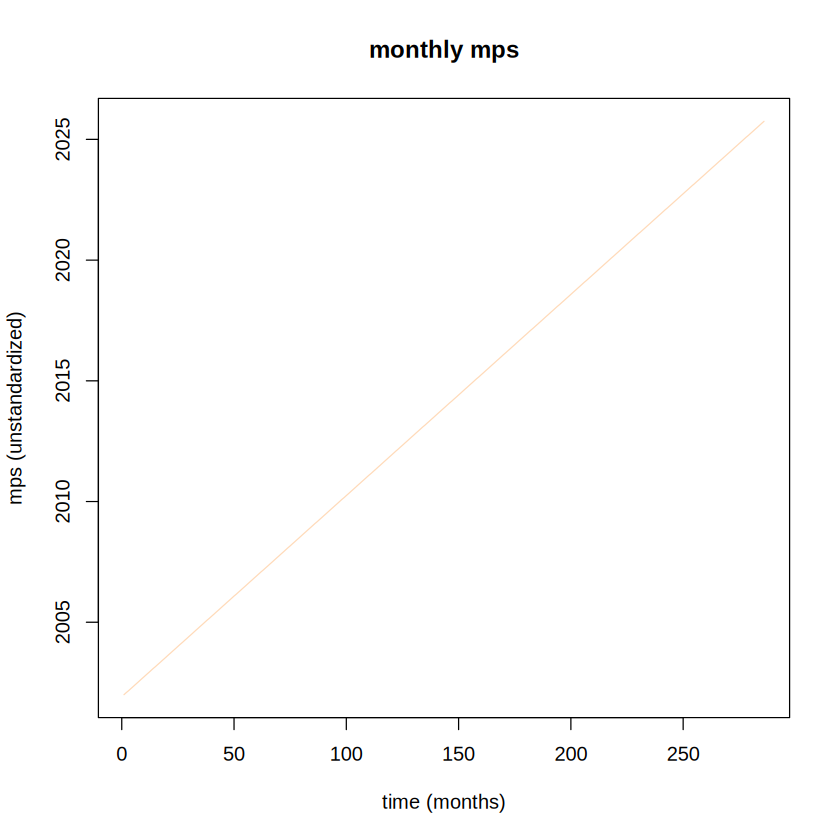

In [ ]:
cat('Length of monthly_mps: \n')
print(nrow(monthly_mps))

cat('sample period \n')
cat(strrep('*', 50), '\n')
cat('start period of sample: ', as.character(monthly_mps$month[1], '\n'))
cat('end period of sample: ', as.character(tail(monthly_mps$month,1), '\n'))

# append numeric cols to this list for simple plotting
numeric_cols <- monthly_mps[, sapply(monthly_mps, is.numeric), drop = FALSE]

# grabbed from last notebook
simple_summary <- sapply(numeric_cols, function(x) c(
  Mean = mean(x, na.rm = TRUE),
  Std_Dev = sd(x, na.rm = TRUE),
  Min = min(x, na.rm = TRUE),
  Max = max(x, na.rm = TRUE)
))

simple_summary

# plot
plot(
  x = monthly_mps$month_date,
  y = monthly_mps$mps,
  type='l',
  main = 'monthly mps',
  xlab = 'time (months)',
  ylab = 'mps (unstandardized)',
  col = 'peachpuff',
  lwd=1
)



**(ii) Download and Describe the Predictors**. For each predictor, state the source, the series code, the frequency and the units. Plot each series in levels.

In [ ]:
install.packages('patchwork')
library(patchwork)

# HICP annual inflation, euro area, all items (Eurostat)
hicp <- get_eurostat("prc_hicp_manr",
filters = list(geo = "EA20", coicop = "CP00"))

# Economic sentiment indicator, euro area (Read from local CSV to avoid API 404)
# somethings fucked up with this csv file with the time period
esi <- read.csv("esi.csv", stringsAsFactors = FALSE)

# ECB yield curve: AAA spot rates for several maturities (daily)
mats <- c("3M", "6M", "1Y", "2Y", "5Y", "10Y")
yc <- lapply(mats, function(m)
get_data(paste0("YC.B.U2.EUR.4F.G_N_A.SV_C_YM.SR_", m)))

# EURO STOXX 50 (Yahoo Finance); VSTOXX: download the CSV from stoxx.com
getSymbols("^STOXX50E", from = "2001-09-01", src = "yahoo")
stoxx <- data.frame(date = index(STOXX50E),
close = as.numeric(Cl(STOXX50E)))
vstoxx <- read.table("v2tx.csv",
                     header=TRUE,
                     sep = ';',
                     stringsAsFactors = FALSE,
                     strip.white = TRUE)

# Value on the last trading day before each announcement date d
last_before <- function(dates, values, d) values[max(which(dates < d))]

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Table prc_hicp_manr cached at /tmp/RtmpwB6pAb/eurostat/e524f534971ddcbf99402dadbca4956b.rds

Warning message:
“^STOXX50E contains missing values. Some functions will not work if objects contain missing values in the middle of the series. Consider using na.omit(), na.approx(), na.fill(), etc to remove or replace them.”


[1] "STOXX50E"

Warning message in file(file, "rt"):
“cannot open file 'v2tx.csv': No such file or directory”


ERROR: Error in file(file, "rt"): cannot open the connection


# Data Cleaning all dfs

In [ ]:
hicp_cleaned <- hicp %>%
  mutate(date = if ('time' %in% names(.)) as.Date(time) else as.Date(TIME_PERIOD)) %>%
  filter(!is.na(values))
'''
esi_cleaned <- esi %>%
  mutate(
    date_str = as.character(.data[[]]),
    date_str = if_else(nchar(date_str) == 7, paste0(date_str, "-01"), date_str),
    date = as.Date(date_str),
    values = as.numeric(.data[[val_col]])
  ) %>%
  filter(!is.na(date), !is.na(values)) %>%
  select(date, values) %>%
  arrange(date)
  '''

names(yc) <- mats
yc_df <- bind_rows(lapply(names(yc), function(x) {
  df <- yc[[x]]
  df$maturity <- x
  df
})) %>%
  mutate(
    date = as.Date(obstime),
    maturity = factor(maturity, levels = mats)
  ) %>%
    filter(!is.na(obsvalue))

date_vec <- as.character(vstoxx[[1]])
value_vec <- as.character(vstoxx[[3]])

vstoxx_cleaned <- data.frame(
  date = as.Date(date_vec, format='%d.%m.%Y'),
  level = as.numeric(gsub(',', '.', value_vec)),
  stringsAsFactors = FALSE
) %>%
  filter(!is.na(date), !is.na(level))

In [ ]:
# plots

y_col_hicp <- if ('values' %in% names(hicp_cleaned)) 'values' else 'value'

hicp_plot <- ggplot(hicp_cleaned, aes(x=date, y=.data[[y_col_hicp]])) +
  geom_line(color='darkorange', linewidth=0.8) +
  geom_hline(yintercept=2, linetype='dashed', color='peachpuff') +
  labs(
    title='EA HICP Annual Inflation',
    subtitle='All items in EA20, annual % change (∆)',
    x = 'Date',
    y = '%') +
  theme_minimal()

y_col_esi <- if ("values" %in% names(esi_cleaned)) "values" else "value"

esi_plot <- ggplot(esi_cleaned, aes(x=date, y=.data[[y_col_esi]])) +
  geom_line(color='darkorange', linewidth=0.8) +
  geom_hline(yintercept=100, linetype='dashed', color='peachpuff') +
  labs(
    title='EA Economic Sentiment Indicator (ESI)',
    subtitle='Long-Term Average = 100',
    x='Date',
    y='Index') +
    theme_minimal()

  yc_plot <- ggplot(yc_df, aes(x=date, y=obsvalue, color=maturity)) +
    geom_line(linewidth=0.7) +
    labs(
      title='ECB AAA Spot Yield Curve',
      subtitle='Daily Rates Across Varying Maturities',
      x='Date',
      y='Spot Rate (%)',
      color='Maturity') +
      theme_minimal() +
      theme(legend.position = 'bottom')

stoxx_plot <- ggplot(stoxx, aes(x=date, y=close)) +
  geom_line(color='darkorange', linewidth=0.8) +
  labs(
    title='Euro STOXX 50',
    subtitle='Daily Closing Price Level',
    x='Date',
    y='Price Level') +
    theme_minimal()

vstoxx_plot <- ggplot(vstoxx_cleaned, aes(x=date, y=level)) +
  geom_line(color='darkorange', linewidth=0.7) +
  labs(
    title='VSTOXX Volatility Index',
    subtitle='Implied Volatility (Annual %)',
    x='Date',
    y='Index Points') +
    theme_minimal()

((hicp_plot | esi_plot) /
(stoxx_plot | vstoxx_plot) /
yc_plot) + plot_layout(heights = c(1,1,1.3))


**(iii) Construct $z_{t-1}$**. Compute the changes defined in Section 2.2 relative to the reference day $r_t$ of each month. Explain how you deal with weekends and holidays (use the last available trading day before d), and why no predictor uses information from the announcement day or later.

**(iv) Describe the Predictors.** Report summary statistics and the correlation matrix of the predictors. Are any of them highly correlated (e.g. STOXX and VSTOXX changes)? What does that imply for the individual t tests?

# Schedule

**(iv) Describe the Predictors**. Report summary statistics and the correlation matrix of the predictors. Are any of them highly correlated (e.g. STOXX and VSTOXX changes)? What does that imply for the individual t tests?

**(v) Estimate the Regression**. Regress $mps_t$ on a constant and $x_{t-1}$ by OLS. Report the estimates, standard errors, t-stats, $R^2$, and adjusted $R^2$, and interpret the sign of each coefficient (e.g. does a stock market rally before the meeting predict a tightening surprise?).

**(vi) Check the Residuals**. Plot the residuals and their ACF. Test for serial correlation (Ljung-Box, Box.test; Breusch-Godfrey, lmtest::bgtest) and for heteroscedasticity (Breush-Pagan, lmtest::bptest). State conclusion.

**(vii) Inference with HAC Standard Errors**. If the residuals show serial correlation or heteroscedasticity, re-estimate the standard errors with the Newey-West estimator (sandwich::NeweyWest, with the truncation lag stated, e.g.: $L = [4(T/100)^{2/9}]$ Compare OLS and HAC standard errors.

**(viii) Test individual and joint significance**. Test each ${\beta}_j = 0$ and the joint hypothesis $\beta = 0$ (Wald test with the HAC covariance matrix, lmtest::waldtest or car::linearHypothesis). Is the surprise predictable?

**(ix) Robustness Check**. Re-estimate with (a) different horizons for the market variables (1 day, 1 month), (b) only the months with an announcement (dropping the months with $mps_t = 0$), (c) the yield-curve spread instead of PC2, and (d) excluding the 2008-2009 crisis or the 2020 COVID period. Do the conclusions change?

**(x) Interpret**. What does predictability (or its absence) imply for using $mps_t$ as a monetary policy shock? If it is predcitable, construct an 'orthogonalised' surprise as the residual $\hat{u}_t$ from the regression, as Bauer and Swanson (2022) do, and compare it with $mps_t$ in a plot. Compare your findings with those of Bauer and Swanson for the U.S.

A brief summary of this second part will have to be included in the short report summarizing all parts of the project.